# Pertemuan 7 — Teori Dasar: Regresi Linier dan Non-Linier

Regresi adalah teknik dalam statistika dan pembelajaran mesin untuk memodelkan hubungan antara satu atau lebih variabel independen (X) dengan satu variabel dependen (Y) yang bersifat kontinu. Berbeda dengan klasifikasi yang memprediksi label kategori, regresi menghasilkan keluaran berupa angka, misalnya harga rumah, gaji, atau biaya medis.

Notebook ini memuat perhitungan yang terdapat pada materi teori dasar, yaitu regresi linier sederhana, evaluasi model dengan RSS dan R², regresi linier berganda, dan regresi polynomial. Contoh yang dipakai adalah data diameter pizza beserta harganya, mengikuti modul praktikum.

Sumber: [Teori Dasar — Regresi Linier dan Non Linier](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-regresi/teori-dasar/regresi-linier-dan-non-linier).

## 1. Menyiapkan pustaka

Sel berikut memuat pustaka untuk perhitungan numerik, pengolahan data, visualisasi, serta model regresi dari scikit-learn.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

## 2. Simple Linear Regression — estimasi parameter

Regresi linier sederhana memodelkan hubungan satu variabel independen dengan satu variabel dependen dalam bentuk garis lurus:

$$Y = \beta_0 + \beta_1 X$$

Parameter model diestimasi dengan metode kuadrat terkecil. Koefisien $\beta_1$ (kemiringan garis) dihitung dari perbandingan jumlah perkalian deviasi X dan Y terhadap jumlah kuadrat deviasi X, sedangkan $\beta_0$ (intercept) dihitung dari rata-rata kedua variabel:

$$\beta_1 = \frac{\sum (X_i - \bar{X})(Y_i - \bar{Y})}{\sum (X_i - \bar{X})^2}, \qquad \beta_0 = \bar{Y} - \beta_1 \bar{X}$$

Data yang dipakai adalah lima ukuran diameter pizza (inci) dengan harganya (dolar).

In [2]:
diameter_pizza = np.array([6, 8, 10, 14, 18])
harga_pizza = np.array([7, 9, 13, 17.5, 18])

x_bar = diameter_pizza.mean()
y_bar = harga_pizza.mean()

beta_1 = np.sum((diameter_pizza - x_bar) * (harga_pizza - y_bar)) / np.sum((diameter_pizza - x_bar) ** 2)
beta_0 = y_bar - beta_1 * x_bar

print(f"Rata-rata diameter (X) : {x_bar:.2f} inci")
print(f"Rata-rata harga (Y)    : {y_bar:.2f} dolar")
print(f"Koefisien beta_1       : {beta_1:.4f}")
print(f"Intercept beta_0       : {beta_0:.4f}")

Rata-rata diameter (X) : 11.20 inci
Rata-rata harga (Y)    : 12.90 dolar
Koefisien beta_1       : 0.9763
Intercept beta_0       : 1.9655


## 3. Prediksi dan visualisasi garis regresi

Dengan nilai $\beta_0 \approx 1.82$ dan $\beta_1 \approx 0.974$, model dapat dituliskan sebagai $HargaPizza = 1.82 + 0.974 \times DiameterPizza$. Model ini dipakai untuk memprediksi harga pizza berukuran 12 inci dan digambarkan bersama data aslinya.

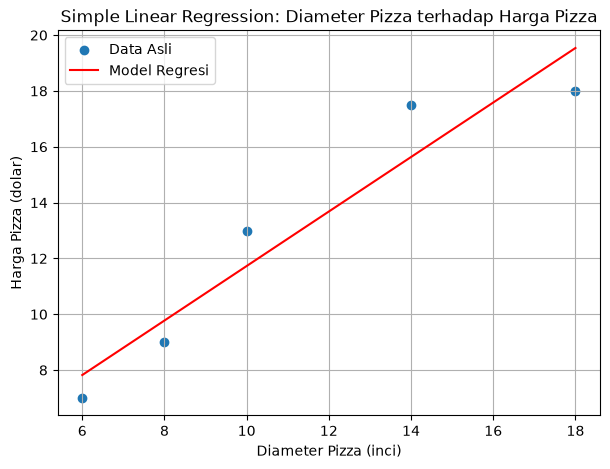

Prediksi harga pizza diameter 12 inci: 13.68 dolar


In [3]:
harga_prediksi = beta_0 + beta_1 * diameter_pizza

plt.figure(figsize=(7, 5))
plt.scatter(diameter_pizza, harga_pizza, label="Data Asli")
plt.plot(diameter_pizza, harga_prediksi, color="red", label="Model Regresi")
plt.xlabel("Diameter Pizza (inci)")
plt.ylabel("Harga Pizza (dolar)")
plt.title("Simple Linear Regression: Diameter Pizza terhadap Harga Pizza")
plt.legend()
plt.grid(True)
plt.show()

harga_12_inchi = beta_0 + beta_1 * 12
print(f"Prediksi harga pizza diameter 12 inci: {harga_12_inchi:.2f} dolar")

## 4. Evaluasi model dengan RSS dan R²

Kualitas model regresi diukur dari seberapa dekat nilai prediksi dengan nilai sebenarnya. Residual Sum of Squares (RSS) menjumlahkan kuadrat selisih nilai sebenarnya dengan nilai prediksi, sedangkan Total Sum of Squares (TSS) mengukur keragaman nilai sebenarnya terhadap rata-ratanya. Rasio keduanya menghasilkan koefisien determinasi:

$$RSS = \sum (Y_i - \hat{Y}_i)^2, \qquad R^2 = 1 - \frac{RSS}{TSS}$$

Semakin kecil RSS dan semakin dekat $R^2$ ke nilai 1, semakin baik model menjelaskan keragaman data. Sebagai pelengkap dihitung pula Mean Absolute Error (MAE) dan Mean Squared Error (MSE).

In [4]:
RSS = np.sum((harga_pizza - harga_prediksi) ** 2)
TSS = np.sum((harga_pizza - harga_pizza.mean()) ** 2)
R2 = 1 - (RSS / TSS)

mae = mean_absolute_error(harga_pizza, harga_prediksi)
mse = mean_squared_error(harga_pizza, harga_prediksi)

print("Prediksi harga pizza      :", np.round(harga_prediksi, 3))
print(f"Residual Sum of Squares   : {RSS:.5f}")
print(f"Total Sum of Squares      : {TSS:.2f}")
print(f"R-squared (R2)            : {R2:.4f}")
print(f"MAE (Mean Absolute Error) : {mae:.4f}")
print(f"MSE (Mean Squared Error)  : {mse:.4f}")

Prediksi harga pizza      : [ 7.823  9.776 11.728 15.634 19.539]
Residual Sum of Squares   : 8.74784
Total Sum of Squares      : 97.20
R-squared (R2)            : 0.9100
MAE (Mean Absolute Error) : 1.2552
MSE (Mean Squared Error)  : 1.7496


## 5. Multiple Linear Regression

Regresi linier berganda merupakan perluasan regresi linier sederhana karena memakai lebih dari satu variabel independen:

$$Y = \alpha + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

Pada contoh ini dipakai dua fitur, yaitu diameter pizza dan jumlah topping. Data dibagi menjadi lima baris data latih dan lima baris data uji, lalu model dilatih dengan `LinearRegression` dari scikit-learn.

In [5]:
# Data training
X_train = np.array([[6, 2], [8, 1], [10, 0], [14, 2], [18, 3]])
y_train = np.array([7, 9, 13, 17.5, 18])

# Data testing
X_test = np.array([[8, 2], [9, 0], [11, 2], [16, 2], [12, 0]])
y_test = np.array([11, 8.5, 15, 18, 11])

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Intercept : {model.intercept_:.4f}")
print(f"Koefisien : {np.round(model.coef_, 4)}")
print("\nHasil Prediksi Harga Pizza:")
for i in range(len(y_pred)):
    print(f"Data Test {i + 1}: Prediksi ${y_pred[i]:.2f}, Target ${y_test[i]:.2f}")

print(f"\nR-squared (R2): {r2_score(y_test, y_pred):.2f}")

Intercept : 2.0620
Koefisien : [ 1.101  -0.9331]

Hasil Prediksi Harga Pizza:
Data Test 1: Prediksi $9.00, Target $11.00
Data Test 2: Prediksi $11.97, Target $8.50
Data Test 3: Prediksi $12.31, Target $15.00
Data Test 4: Prediksi $17.81, Target $18.00
Data Test 5: Prediksi $15.27, Target $11.00

R-squared (R2): 0.27


## 6. Regresi Polynomial

Regresi polynomial dipakai ketika hubungan antara variabel independen dan dependen tidak membentuk garis lurus. Model ini menambahkan pangkat dari fitur sebagai variabel baru, sehingga persamaannya berbentuk:

$$Y = \beta_0 + \beta_1 X + \beta_2 X^2 + \dots + \beta_n X^n$$

Fitur awal diperluas dengan `PolynomialFeatures` berderajat 2, kemudian model linier dilatih pada fitur hasil perluasan tersebut. Derajat yang terlalu tinggi berisiko overfitting, sehingga derajat polynomial perlu dipilih dengan hati-hati.

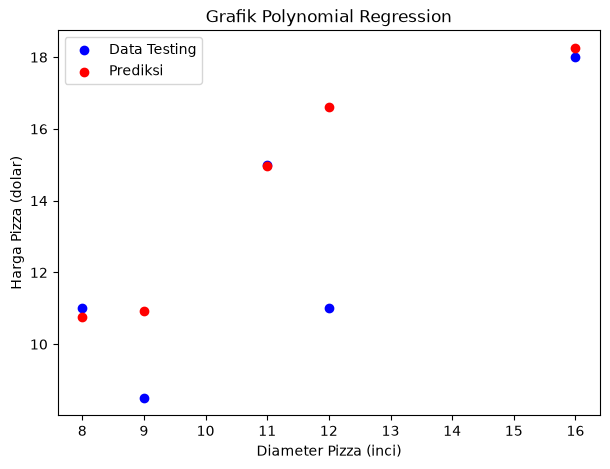

R-squared (R2): 0.34


In [6]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly = LinearRegression()
model_poly.fit(X_train_poly, y_train)
y_pred_poly = model_poly.predict(X_test_poly)

plt.figure(figsize=(7, 5))
plt.scatter(X_test[:, 0], y_test, color="blue", label="Data Testing")
plt.scatter(X_test[:, 0], y_pred_poly, color="red", label="Prediksi")
plt.title("Grafik Polynomial Regression")
plt.xlabel("Diameter Pizza (inci)")
plt.ylabel("Harga Pizza (dolar)")
plt.legend()
plt.show()

print(f"R-squared (R2): {r2_score(y_test, y_pred_poly):.2f}")

## Kesimpulan

Regresi linier sederhana memodelkan hubungan satu variabel independen dengan satu variabel dependen, sedangkan regresi linier berganda memakai beberapa variabel independen sekaligus. Nilai parameter pada regresi linier sederhana dapat dihitung langsung dengan metode kuadrat terkecil dan menghasilkan $\beta_0 \approx 1.82$ serta $\beta_1 \approx 0.974$ pada data pizza. Kualitas model diukur dengan RSS, R², MAE, dan MSE. Ketika hubungan antar variabel tidak linier, regresi polynomial dapat menangkap pola tersebut dengan menambahkan pangkat fitur, namun derajat yang terlalu tinggi dapat menyebabkan overfitting.